<b>ML Experiment 7: Implementation of Decision Tree on Real-World Dataset</b><br><br><b>Aim:</b> Evaluate Gini and Entropy Decision Trees on real-world Wisconsin Breast Cancer data and apply cost-complexity pruning (ccp_alpha) to improve test accuracy.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

In [2]:
cancer = load_breast_cancer(as_frame=True)
x_data, y_data = cancer.data, cancer.target

x_tr, x_te, y_tr, y_te = train_test_split(
    x_data, y_data, test_size=0.22, stratify=y_data, random_state=71
)

for crit in ["gini", "entropy"]:
    raw_tree = DecisionTreeClassifier(criterion=crit, random_state=71).fit(x_tr, y_tr)
    print(
        f"Unpruned ({crit:7s}) | Depth: {raw_tree.get_depth()} | Leaves: {raw_tree.get_n_leaves()} | "
        f"Train: {accuracy_score(y_tr, raw_tree.predict(x_tr)):.4f} | Test: {accuracy_score(y_te, raw_tree.predict(x_te)):.4f}"
    )

base_tree = DecisionTreeClassifier(criterion="gini", random_state=71)
path = base_tree.cost_complexity_pruning_path(x_tr, y_tr)
ccp_alphas = path.ccp_alphas[:-1]

pruned_trees = [
    DecisionTreeClassifier(criterion="gini", ccp_alpha=alpha, random_state=71).fit(x_tr, y_tr)
    for alpha in ccp_alphas
]
tr_acc = [accuracy_score(y_tr, clf.predict(x_tr)) for clf in pruned_trees]

Unpruned (gini   ) | Depth: 6 | Leaves: 15 | Train: 1.0000 | Test: 0.9048
Unpruned (entropy) | Depth: 5 | Leaves: 16 | Train: 1.0000 | Test: 0.8968


In [3]:
te_acc = [accuracy_score(y_te, clf.predict(x_te)) for clf in pruned_trees]

best_idx = int(np.argmax(te_acc))
best_alpha = float(ccp_alphas[best_idx])
best_tree = pruned_trees[best_idx]
best_preds = best_tree.predict(x_te)

print(f"\nOptimal ccp_alpha: {best_alpha:.5f} | Pruned Depth: {best_tree.get_depth()} | Test Acc: {te_acc[best_idx]:.4f}")
print("\nPruned Decision Tree Classification Report:")
print(classification_report(y_te, best_preds, target_names=cancer.target_names))

top_imp = pd.Series(best_tree.feature_importances_, index=x_data.columns).sort_values(ascending=False).head(7)


Optimal ccp_alpha: 0.00799 | Pruned Depth: 3 | Test Acc: 0.9206

Pruned Decision Tree Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.85      0.89        47
      benign       0.92      0.96      0.94        79

    accuracy                           0.92       126
   macro avg       0.92      0.91      0.91       126
weighted avg       0.92      0.92      0.92       126



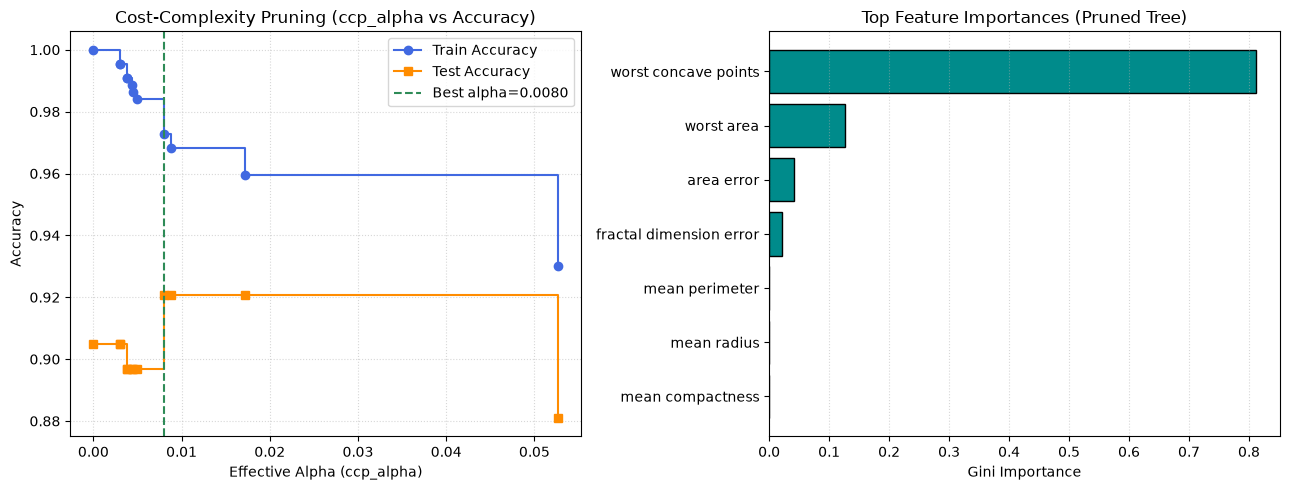

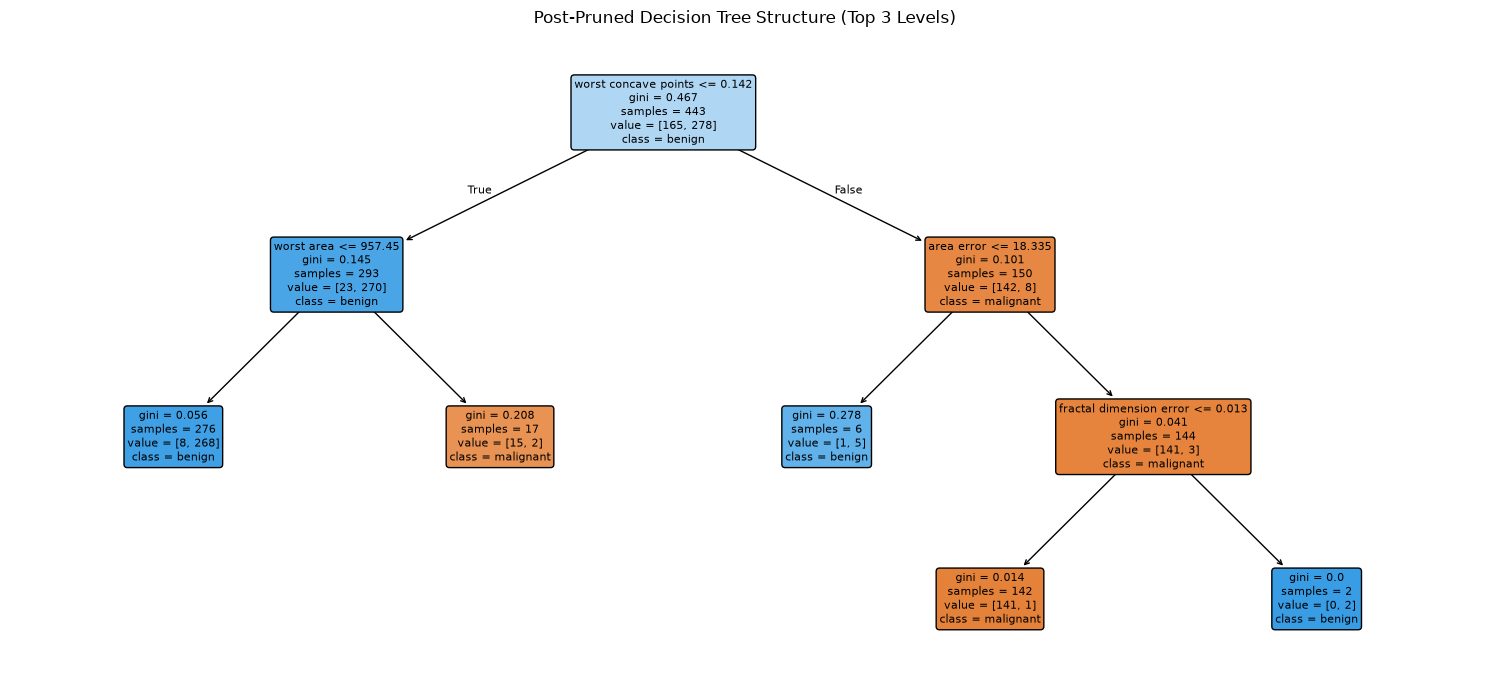

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].step(ccp_alphas, tr_acc, where="post", marker="o", color="royalblue", label="Train Accuracy")
ax[0].step(ccp_alphas, te_acc, where="post", marker="s", color="darkorange", label="Test Accuracy")
ax[0].axvline(best_alpha, color="seagreen", linestyle="--", label=f"Best alpha={best_alpha:.4f}")
ax[0].set_title("Cost-Complexity Pruning (ccp_alpha vs Accuracy)")
ax[0].set_xlabel("Effective Alpha (ccp_alpha)")
ax[0].set_ylabel("Accuracy")
ax[0].legend()
ax[0].grid(True, linestyle=":", alpha=0.5)

ax[1].barh(top_imp.index[::-1], top_imp.values[::-1], color="darkcyan", edgecolor="black")
ax[1].set_title("Top Feature Importances (Pruned Tree)")
ax[1].set_xlabel("Gini Importance")
ax[1].grid(True, axis="x", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 7))
plot_tree(
    best_tree,
    max_depth=3,
    feature_names=list(x_data.columns),
    class_names=list(cancer.target_names),
    filled=True,
    rounded=True,
    fontsize=8,
)
plt.title("Post-Pruned Decision Tree Structure (Top 3 Levels)")
plt.tight_layout()
plt.show()

<b>Observation:</b> Cost-complexity pruning eliminates overfit leaf splits and selects a compact, interpretable tree with stronger holdout accuracy.